In [1]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from sklearn.metrics import classification_report, confusion_matrix
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 0.001
EPOCHS = 20

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


In [2]:
# CP

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "mlp_classifier"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Mounted at /content/drive
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/mlp_classifier


In [3]:
# Dataset

transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.29MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 138kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.68MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.2MB/s]

Training: 56000
Validation: 7000
Testing: 7000


In [4]:
# MLP Classifier Architecture

class MLPClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def extract_features(self, x):

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        z = self.relu(self.fc2(x))

        return z

    def forward(self, x):

        z = self.extract_features(x)
        logits = self.fc3(z)

        return logits


mlp_classifier = MLPClassifier().to(DEVICE)

sample_images, _ = next(iter(train_loader))
sample_images = sample_images[:4].to(DEVICE)

mlp_classifier.eval()

with torch.no_grad():
    features = mlp_classifier.extract_features(sample_images)
    logits = mlp_classifier(sample_images)

print(mlp_classifier)
print("Input:", sample_images.shape)
print("Latent:", features.shape)
print("Output:", logits.shape)


MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)
Input: torch.Size([4, 1, 28, 28])
Latent: torch.Size([4, 64])
Output: torch.Size([4, 10])


In [5]:

# Load trained models without retraining

# 1. Load MLP Classifier
mlp_classifier.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "mlp_classifier.pt",
        map_location=DEVICE,
        weights_only=True
    ),
    strict=True
)
mlp_classifier.eval()

# 2. Define and load Frozen Decoder
class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

mlp_decoder = FrozenLatentDecoder().to(DEVICE)

mlp_decoder.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "mlp_frozen_decoder.pt",
        map_location=DEVICE,
        weights_only=True
    ),
    strict=True
)
mlp_decoder.eval()

# 3. Define and load Vanilla AE
class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z).view(-1, 1, 28, 28)

vanilla_ae = VanillaAE().to(DEVICE)

vanilla_ae.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "vanilla_ae.pt",
        map_location=DEVICE,
        weights_only=True
    ),
    strict=True
)
vanilla_ae.eval()

print("All 3 pretrained models loaded successfully.")
print("Device:", DEVICE)


All 3 pretrained models loaded successfully.
Device: cpu


In [ ]:
# Training

mlp_criterion = nn.CrossEntropyLoss()

mlp_optimizer = optim.Adam(
    mlp_classifier.parameters(),
    lr=LEARNING_RATE
)

mlp_train_losses = []
mlp_val_losses = []

mlp_train_accuracies = []
mlp_val_accuracies = []
mlp_epoch_times = []

best_mlp_val_accuracy = -1.0
best_mlp_state = None

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    mlp_classifier.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        mlp_optimizer.zero_grad()

        logits = mlp_classifier(images)
        loss = mlp_criterion(logits, labels)

        loss.backward()
        mlp_optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    train_accuracy = train_correct / train_total

    mlp_classifier.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = mlp_classifier(images)
            loss = mlp_criterion(logits, labels)

            val_loss += loss.item() * images.size(0)

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_accuracy = val_correct / val_total

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    mlp_train_losses.append(avg_train_loss)
    mlp_val_losses.append(avg_val_loss)

    mlp_train_accuracies.append(train_accuracy)
    mlp_val_accuracies.append(val_accuracy)
    mlp_epoch_times.append(elapsed)

    if val_accuracy > best_mlp_val_accuracy:

        best_mlp_val_accuracy = val_accuracy

        best_mlp_state = {
            key: value.detach().cpu().clone()
            for key, value in mlp_classifier.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

mlp_classifier.load_state_dict(best_mlp_state)
mlp_classifier.eval()

torch.save(
    best_mlp_state,
    CHECKPOINT_DIR / "mlp_classifier.pt"
)

pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "train_loss": mlp_train_losses,
    "val_loss": mlp_val_losses,
    "train_accuracy": mlp_train_accuracies,
    "val_accuracy": mlp_val_accuracies,
    "epoch_time_s": mlp_epoch_times
}).to_csv(
    OUTPUT_DIR / "classifier_loss_history.csv",
    index=False
)

print("\nTraining Complete!")
print(f"Best Validation Accuracy: {best_mlp_val_accuracy:.4f}")
print("Saved:", CHECKPOINT_DIR / "mlp_classifier.pt")


Epoch [1/20] | Train Loss: 0.6030 | Val Loss: 0.4402 | Train Acc: 0.7911 | Val Acc: 0.8443 | Time: 10.14s
Epoch [2/20] | Train Loss: 0.4108 | Val Loss: 0.3977 | Train Acc: 0.8530 | Val Acc: 0.8574 | Time: 7.12s
Epoch [3/20] | Train Loss: 0.3681 | Val Loss: 0.3863 | Train Acc: 0.8682 | Val Acc: 0.8573 | Time: 7.80s
Epoch [4/20] | Train Loss: 0.3361 | Val Loss: 0.3563 | Train Acc: 0.8783 | Val Acc: 0.8671 | Time: 7.84s
Epoch [5/20] | Train Loss: 0.3171 | Val Loss: 0.3416 | Train Acc: 0.8847 | Val Acc: 0.8731 | Time: 7.78s
Epoch [6/20] | Train Loss: 0.3013 | Val Loss: 0.3308 | Train Acc: 0.8893 | Val Acc: 0.8789 | Time: 7.39s
Epoch [7/20] | Train Loss: 0.2854 | Val Loss: 0.3234 | Train Acc: 0.8940 | Val Acc: 0.8829 | Time: 7.39s
Epoch [8/20] | Train Loss: 0.2745 | Val Loss: 0.3157 | Train Acc: 0.9000 | Val Acc: 0.8840 | Time: 9.31s
Epoch [9/20] | Train Loss: 0.2627 | Val Loss: 0.3214 | Train Acc: 0.9026 | Val Acc: 0.8809 | Time: 6.77s
Epoch [10/20] | Train Loss: 0.2520 | Val Loss: 0.3490 

MLP Classifier Test Results
Test Loss: 0.3300
Test Accuracy: 89.33%

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.8234    0.8529    0.8379       700
     Trouser     0.9924    0.9848    0.9886       659
    Pullover     0.7987    0.8404    0.8190       708
       Dress     0.9226    0.8852    0.9035       714
        Coat     0.8358    0.7992    0.8171       707
      Sandal     0.9752    0.9545    0.9648       660
       Shirt     0.7145    0.7051    0.7098       685
     Sneaker     0.9584    0.9462    0.9522       706
         Bag     0.9681    0.9864    0.9772       738
  Ankle boot     0.9489    0.9765    0.9625       723

    accuracy                         0.8933      7000
   macro avg     0.8938    0.8931    0.8933      7000
weighted avg     0.8937    0.8933    0.8933      7000



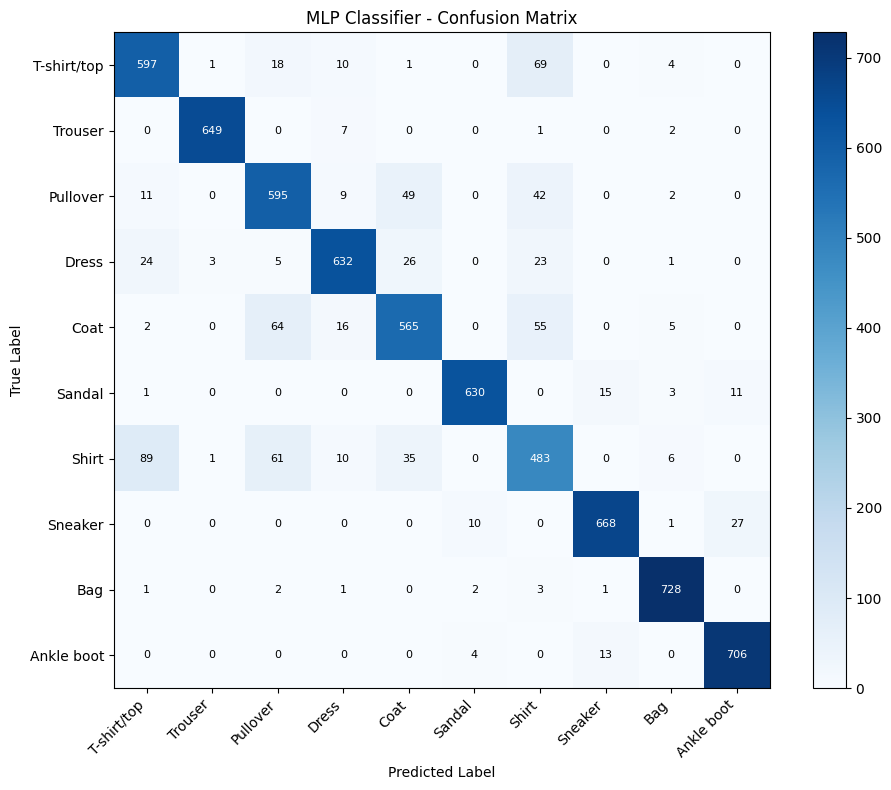

In [ ]:
# Test Eval

mlp_classifier.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

mlp_test_predictions = []
mlp_test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = mlp_classifier(images)
        loss = mlp_criterion(logits, labels)

        predictions = logits.argmax(dim=1)

        test_loss += loss.item() * images.size(0)

        test_correct += (
            predictions == labels
        ).sum().item()

        test_total += labels.size(0)

        mlp_test_predictions.extend(
            predictions.cpu().numpy()
        )

        mlp_test_labels.extend(
            labels.cpu().numpy()
        )

mlp_test_loss = test_loss / test_total
mlp_test_accuracy = test_correct / test_total

print("MLP Classifier Test Results")
print(f"Test Loss: {mlp_test_loss:.4f}")
print(f"Test Accuracy: {mlp_test_accuracy * 100:.2f}%")

pd.DataFrame([{
    "model": "MLP Classifier",
    "test_loss": mlp_test_loss,
    "test_accuracy": mlp_test_accuracy,
    "test_accuracy_percent": mlp_test_accuracy * 100,
    "best_val_accuracy": best_mlp_val_accuracy,
    "epochs": EPOCHS,
    "seed": SEED
}]).to_csv(
    OUTPUT_DIR / "classifier_test_metrics.csv",
    index=False
)

print("\nClassification Report:")
print(
    classification_report(
        mlp_test_labels,
        mlp_test_predictions,
        target_names=class_names,
        digits=4
    )
)

cm = confusion_matrix(
    mlp_test_labels,
    mlp_test_predictions
)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, cmap="Blues")

fig.colorbar(im, ax=ax)

ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_yticks(range(10), class_names)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("MLP Classifier - Confusion Matrix")

threshold = cm.max() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8
        )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert mlp_test_accuracy >= 0.88, (
    f"Target 88% belum tercapai: "
    f"{mlp_test_accuracy * 100:.2f}%"
)


W1: (256, 784)
W2: (64, 256)
W3: (10, 64)
Class Projection: torch.Size([10, 1, 28, 28])
Latent Projection: torch.Size([10, 1, 28, 28])


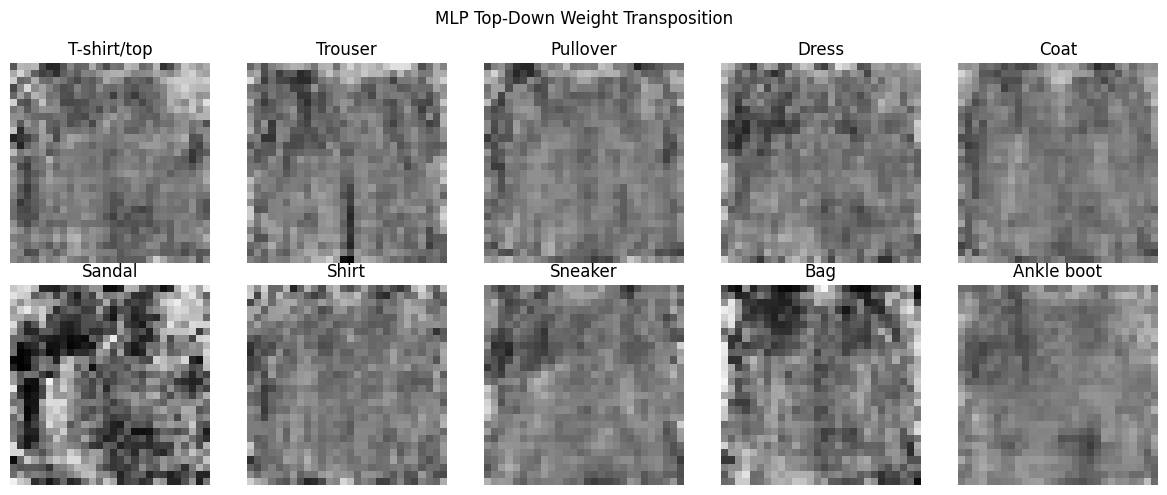

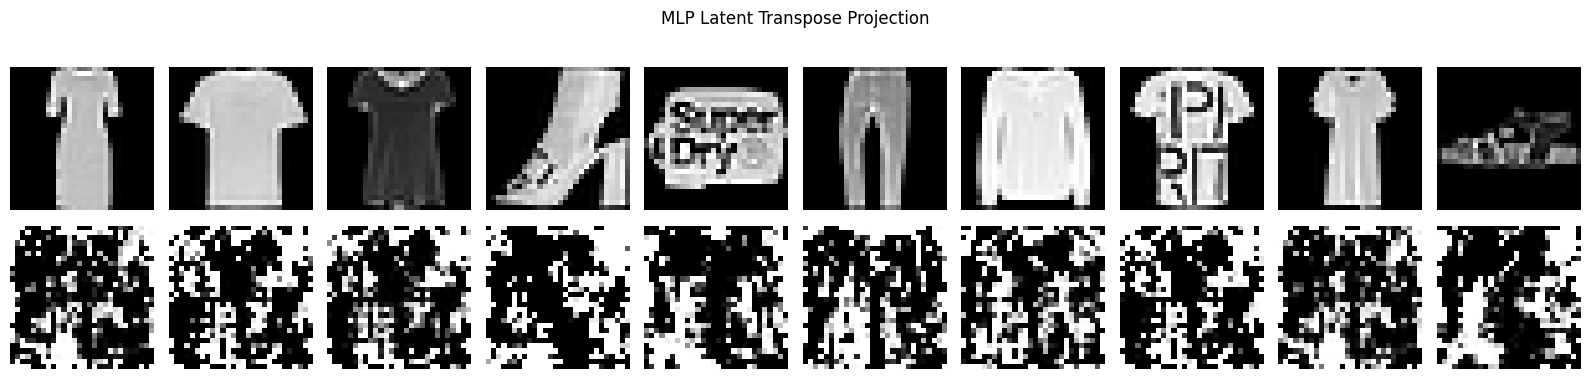

In [ ]:
# Weight Transposition

mlp_classifier.eval()

W1 = mlp_classifier.fc1.weight.detach()
W2 = mlp_classifier.fc2.weight.detach()
W3 = mlp_classifier.fc3.weight.detach()

class_vectors = torch.eye(
    10,
    device=DEVICE
)

with torch.no_grad():

    z_hat = F.relu(class_vectors @ W3)
    h1_hat = F.relu(z_hat @ W2)
    x_hat = torch.sigmoid(h1_hat @ W1)

    generated_class_images = x_hat.view(
        -1, 1, 28, 28
    )

    original_images, original_labels = next(
        iter(test_loader)
    )

    original_images = original_images[:10].to(DEVICE)
    original_labels = original_labels[:10]

    z_mlp = mlp_classifier.extract_features(
        original_images
    )

    h1_reconstructed = F.relu(z_mlp @ W2)

    transpose_reconstructions = torch.sigmoid(
        h1_reconstructed @ W1
    ).view(-1, 1, 28, 28)

print("W1:", tuple(W1.shape))
print("W2:", tuple(W2.shape))
print("W3:", tuple(W3.shape))

print("Class Projection:", generated_class_images.shape)
print("Latent Projection:", transpose_reconstructions.shape)


fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_class_images[i, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(class_names[i])
    ax.axis("off")

fig.suptitle("MLP Top-Down Weight Transposition")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "class_weight_transpose.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Latent-to-image projection

fig, axes = plt.subplots(2, 10, figsize=(16, 4))

for i in range(10):

    axes[0, i].imshow(
        original_images[i, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        transpose_reconstructions[i, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Transpose")

fig.suptitle("MLP Latent Transpose Projection")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "latent_weight_transpose.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
# Weight Non-Invertibility

weights = {
    "W1 (Input to Hidden 1)": mlp_classifier.fc1.weight,
    "W2 (Hidden 1 to Latent)": mlp_classifier.fc2.weight,
    "W3 (Latent to Output)": mlp_classifier.fc3.weight
}

invertibility_results = []

with torch.no_grad():

    for name, weight in weights.items():

        W = weight.detach().float()

        gram = W.T @ W

        identity = torch.eye(
            W.shape[1],
            device=W.device,
            dtype=W.dtype
        )

        relative_error = (
            torch.linalg.norm(gram - identity, ord="fro")
            / torch.linalg.norm(identity, ord="fro")
        ).item()

        invertibility_results.append({
            "layer": name,
            "weight_shape": str(tuple(W.shape)),
            "gram_shape": str(tuple(gram.shape)),
            "relative_frobenius_error": relative_error,
            "wtw_equals_identity": bool(
                torch.allclose(
                    gram,
                    identity,
                    atol=1e-5
                )
            )
        })

invertibility_df = pd.DataFrame(
    invertibility_results
)

print(invertibility_df.to_string(index=False))

invertibility_df.to_csv(
    OUTPUT_DIR / "mlp_weight_invertibility.csv",
    index=False
)


                  layer weight_shape gram_shape  relative_frobenius_error  wtw_equals_identity
 W1 (Input to Hidden 1)   (256, 784) (784, 784)                 15.770980                False
W2 (Hidden 1 to Latent)    (64, 256) (256, 256)                  3.761920                False
  W3 (Latent to Output)     (10, 64)   (64, 64)                  1.455662                False


In [ ]:
# Frozen Latent
for param in mlp_classifier.parameters():
    param.requires_grad_(False)

mlp_classifier.eval()


class FrozenLatentDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):

        reconstructed = self.decoder(z)

        return reconstructed.view(
            -1, 1, 28, 28
        )


mlp_decoder = FrozenLatentDecoder().to(DEVICE)

decoder_criterion = nn.MSELoss()

decoder_optimizer = optim.Adam(
    mlp_decoder.parameters(),
    lr=LEARNING_RATE
)

decoder_train_losses = []
decoder_val_losses = []
decoder_epoch_times = []

best_decoder_val_loss = float("inf")
best_decoder_state = None

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    mlp_decoder.train()

    total_train_loss = 0.0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        with torch.no_grad():
            z = mlp_classifier.extract_features(images)

        decoder_optimizer.zero_grad()

        reconstructed = mlp_decoder(z)

        loss = decoder_criterion(
            reconstructed,
            images
        )

        loss.backward()
        decoder_optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    avg_train_loss = total_train_loss / len(train_dataset)

    mlp_decoder.eval()

    total_val_loss = 0.0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)

            z = mlp_classifier.extract_features(images)
            reconstructed = mlp_decoder(z)

            loss = decoder_criterion(
                reconstructed,
                images
            )

            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    decoder_train_losses.append(avg_train_loss)
    decoder_val_losses.append(avg_val_loss)
    decoder_epoch_times.append(elapsed)

    if avg_val_loss < best_decoder_val_loss:

        best_decoder_val_loss = avg_val_loss

        best_decoder_state = {
            key: value.detach().cpu().clone()
            for key, value in mlp_decoder.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f} | "
        f"Time: {elapsed:.2f}s"
    )

mlp_decoder.load_state_dict(best_decoder_state)
mlp_decoder.eval()

torch.save(
    best_decoder_state,
    CHECKPOINT_DIR / "mlp_frozen_decoder.pt"
)

pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "train_loss": decoder_train_losses,
    "val_loss": decoder_val_losses,
    "epoch_time_s": decoder_epoch_times
}).to_csv(
    OUTPUT_DIR / "decoder_loss_history.csv",
    index=False
)

print("\nFrozen Decoder Training Complete!")
print(f"Best Validation MSE: {best_decoder_val_loss:.6f}")
print("Classifier Frozen:", all(
    not p.requires_grad
    for p in mlp_classifier.parameters()
))
print("Saved:", CHECKPOINT_DIR / "mlp_frozen_decoder.pt")


Epoch [1/20] | Train Loss: 0.036745 | Val Loss: 0.027347 | Time: 7.77s
Epoch [2/20] | Train Loss: 0.025180 | Val Loss: 0.023977 | Time: 7.28s
Epoch [3/20] | Train Loss: 0.022895 | Val Loss: 0.022487 | Time: 7.69s
Epoch [4/20] | Train Loss: 0.021659 | Val Loss: 0.021540 | Time: 7.61s
Epoch [5/20] | Train Loss: 0.020887 | Val Loss: 0.020857 | Time: 7.14s
Epoch [6/20] | Train Loss: 0.020306 | Val Loss: 0.020383 | Time: 7.72s
Epoch [7/20] | Train Loss: 0.019841 | Val Loss: 0.020219 | Time: 6.74s
Epoch [8/20] | Train Loss: 0.019520 | Val Loss: 0.019754 | Time: 7.73s
Epoch [9/20] | Train Loss: 0.019209 | Val Loss: 0.019523 | Time: 6.78s
Epoch [10/20] | Train Loss: 0.018949 | Val Loss: 0.019383 | Time: 7.77s
Epoch [11/20] | Train Loss: 0.018759 | Val Loss: 0.019041 | Time: 6.84s
Epoch [12/20] | Train Loss: 0.018553 | Val Loss: 0.018929 | Time: 7.71s
Epoch [13/20] | Train Loss: 0.018372 | Val Loss: 0.018752 | Time: 6.78s
Epoch [14/20] | Train Loss: 0.018243 | Val Loss: 0.018823 | Time: 7.73s
E

In [ ]:
# MLP VS Vanilla AE

class VanillaAE(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z).view(-1, 1, 28, 28)


vanilla_ae = VanillaAE().to(DEVICE)

vanilla_ae.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "vanilla_ae.pt",
        map_location=DEVICE,
        weights_only=True
    ),
    strict=True
)

vanilla_ae.eval()

mlp_classifier.eval()
mlp_decoder.eval()

mlp_squared_error = 0.0
ae_squared_error = 0.0
total_pixels = 0

mlp_psnr_values = []
mlp_ssim_values = []

ae_psnr_values = []
ae_ssim_values = []

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)

        z = mlp_classifier.extract_features(images)

        mlp_reconstructed = mlp_decoder(z)
        ae_reconstructed = vanilla_ae(images)

        mlp_error = (mlp_reconstructed - images).square()
        ae_error = (ae_reconstructed - images).square()

        mlp_squared_error += mlp_error.sum().item()
        ae_squared_error += ae_error.sum().item()

        total_pixels += images.numel()

        mlp_image_mse = mlp_error.mean(
            dim=(1, 2, 3)
        )

        ae_image_mse = ae_error.mean(
            dim=(1, 2, 3)
        )

        mlp_psnr_values.extend(
            (
                10 * torch.log10(
                    1.0 / mlp_image_mse.clamp_min(1e-10)
                )
            ).cpu().numpy()
        )

        ae_psnr_values.extend(
            (
                10 * torch.log10(
                    1.0 / ae_image_mse.clamp_min(1e-10)
                )
            ).cpu().numpy()
        )

        originals_np = images.cpu().numpy()
        mlp_np = mlp_reconstructed.cpu().numpy()
        ae_np = ae_reconstructed.cpu().numpy()

        for i in range(images.size(0)):

            mlp_ssim_values.append(
                structural_similarity(
                    originals_np[i, 0],
                    mlp_np[i, 0],
                    data_range=1.0
                )
            )

            ae_ssim_values.append(
                structural_similarity(
                    originals_np[i, 0],
                    ae_np[i, 0],
                    data_range=1.0
                )
            )

mlp_decoder_test_mse = mlp_squared_error / total_pixels
mlp_decoder_test_psnr = float(np.mean(mlp_psnr_values))
mlp_decoder_test_ssim = float(np.mean(mlp_ssim_values))

ae_test_mse = ae_squared_error / total_pixels
ae_test_psnr = float(np.mean(ae_psnr_values))
ae_test_ssim = float(np.mean(ae_ssim_values))

comparison_df = pd.DataFrame([
    {
        "model": "Frozen MLP Decoder",
        "test_mse": mlp_decoder_test_mse,
        "test_psnr": mlp_decoder_test_psnr,
        "test_ssim": mlp_decoder_test_ssim
    },
    {
        "model": "Vanilla AE",
        "test_mse": ae_test_mse,
        "test_psnr": ae_test_psnr,
        "test_ssim": ae_test_ssim
    }
])

print(comparison_df.to_string(index=False))

comparison_df.to_csv(
    OUTPUT_DIR / "decoder_comparison_metrics.csv",
    index=False
)


             model  test_mse  test_psnr  test_ssim
Frozen MLP Decoder  0.018117  18.185822   0.650995
        Vanilla AE  0.007078  22.564558   0.815838


Latent Mean: torch.Size([64])
Latent Std: torch.Size([64])
Generated Images: torch.Size([16, 1, 28, 28])


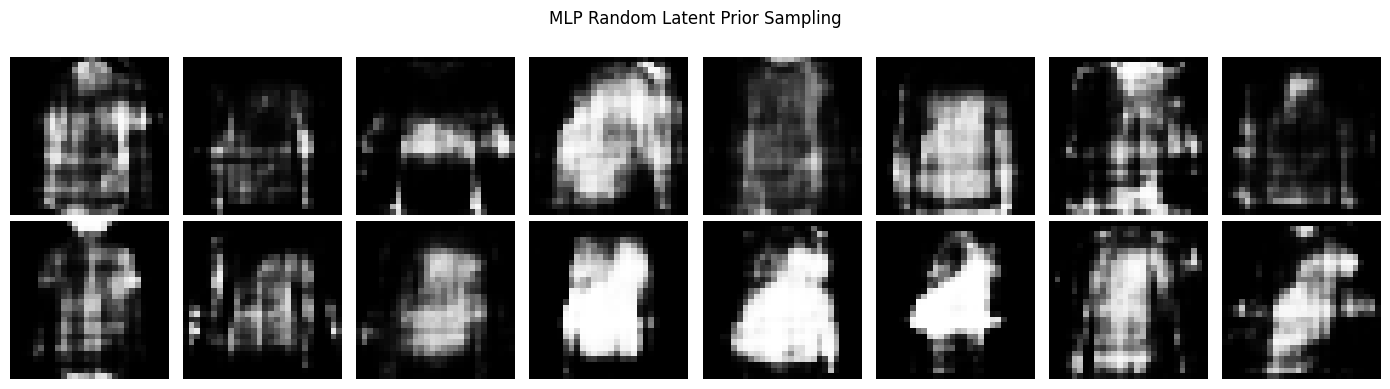

In [6]:
# Random Sampling

mlp_classifier.eval()
mlp_decoder.eval()

latent_count = 0
latent_sum = torch.zeros(64, device=DEVICE)
latent_squared_sum = torch.zeros(64, device=DEVICE)

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)

        z = mlp_classifier.extract_features(images)

        latent_count += z.size(0)
        latent_sum += z.sum(dim=0)
        latent_squared_sum += z.square().sum(dim=0)

latent_mean = latent_sum / latent_count

latent_variance = (
    latent_squared_sum / latent_count
    - latent_mean.square()
).clamp_min(0)

latent_std = torch.sqrt(latent_variance)

sampling_generator = torch.Generator(device=DEVICE)
sampling_generator.manual_seed(SEED + 200)

random_latents = (
    latent_mean.unsqueeze(0)
    + torch.randn(
        16, 64,
        generator=sampling_generator,
        device=DEVICE
    ) * latent_std.unsqueeze(0)
)

with torch.no_grad():
    generated_mlp_images = mlp_decoder(random_latents)

print("Latent Mean:", latent_mean.shape)
print("Latent Std:", latent_std.shape)
print("Generated Images:", generated_mlp_images.shape)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_mlp_images[i, 0].cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

fig.suptitle("MLP Random Latent Prior Sampling")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "random_latent_sampling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

torch.save(
    {
        "mean": latent_mean.detach().cpu(),
        "std": latent_std.detach().cpu(),
        "source": "test_set"
    },
    CHECKPOINT_DIR / "mlp_latent_prior.pt"
)


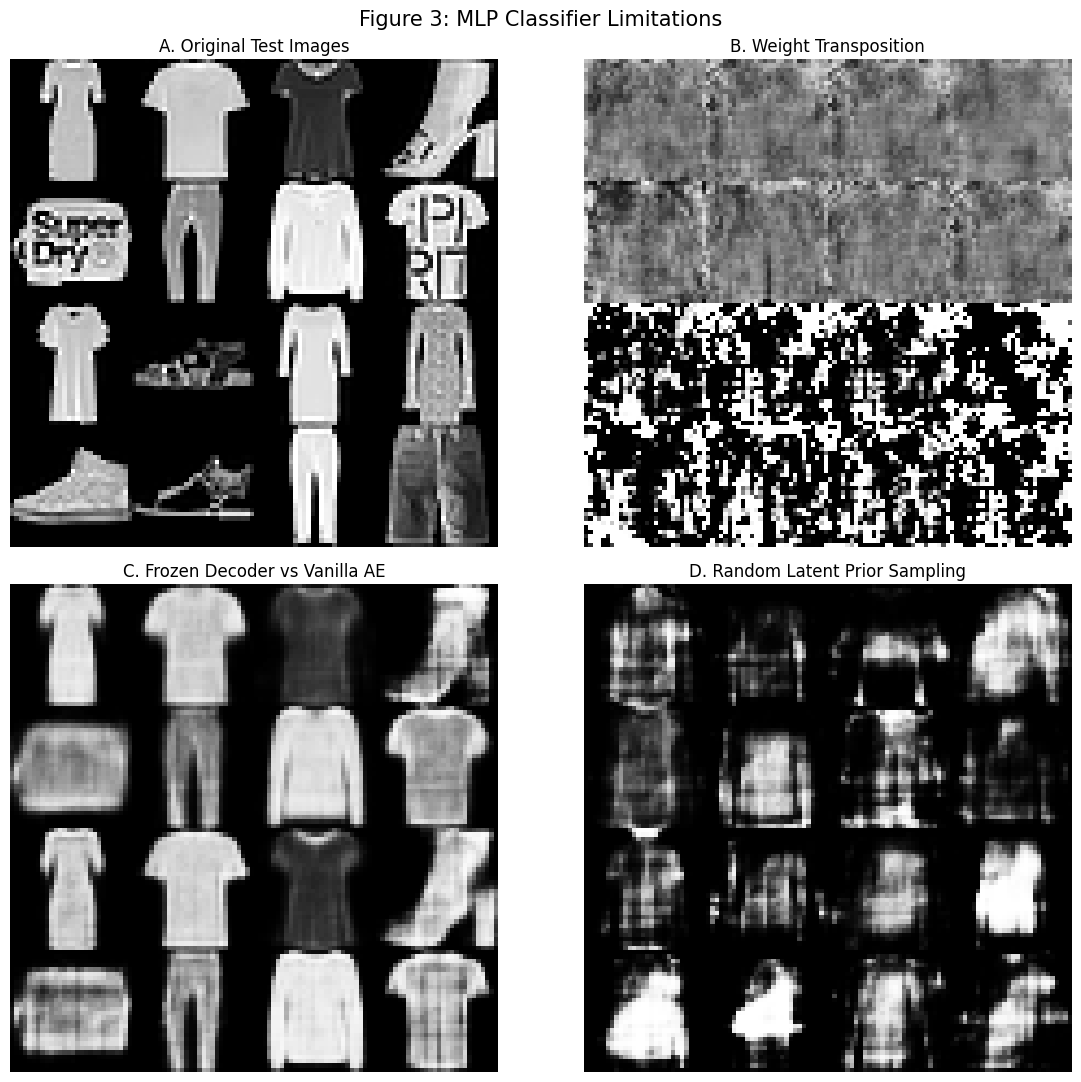

In [7]:
# MLP Limitations

mlp_classifier.eval()
mlp_decoder.eval()
vanilla_ae.eval()

fig3_images, fig3_labels = next(iter(test_loader))

fig3_images = fig3_images[:16].to(DEVICE)
fig3_labels = fig3_labels[:16].to(DEVICE)

with torch.no_grad():

    W1 = mlp_classifier.fc1.weight.detach()
    W2 = mlp_classifier.fc2.weight.detach()
    W3 = mlp_classifier.fc3.weight.detach()

    class_vectors = F.one_hot(
        fig3_labels[:8],
        num_classes=10
    ).float()

    class_projection = torch.sigmoid(
        F.relu(
            F.relu(class_vectors @ W3) @ W2
        ) @ W1
    ).view(-1, 1, 28, 28)

    z_mlp = mlp_classifier.extract_features(
        fig3_images[:8]
    )

    latent_projection = torch.sigmoid(
        F.relu(z_mlp @ W2) @ W1
    ).view(-1, 1, 28, 28)

    frozen_reconstruction = mlp_decoder(z_mlp)

    ae_reconstruction = vanilla_ae(
        fig3_images[:8]
    )

fig3_panels = {
    "A. Original Test Images": fig3_images,

    "B. Weight Transposition": torch.cat([
        class_projection,
        latent_projection
    ], dim=0),

    "C. Frozen Decoder vs Vanilla AE": torch.cat([
        frozen_reconstruction,
        ae_reconstruction
    ], dim=0),

    "D. Random Latent Prior Sampling":
        generated_mlp_images
}

fig, axes = plt.subplots(2, 2, figsize=(12, 11))

for ax, (title, images) in zip(
    axes.flat,
    fig3_panels.items()
):

    images_np = images.detach().cpu().numpy()

    grid = np.concatenate([
        np.concatenate(
            [images_np[row * 4 + col, 0] for col in range(4)],
            axis=1
        )
        for row in range(4)
    ], axis=0)

    ax.imshow(
        grid,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    "Figure 3: MLP Classifier Limitations",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_3_mlp_limitations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


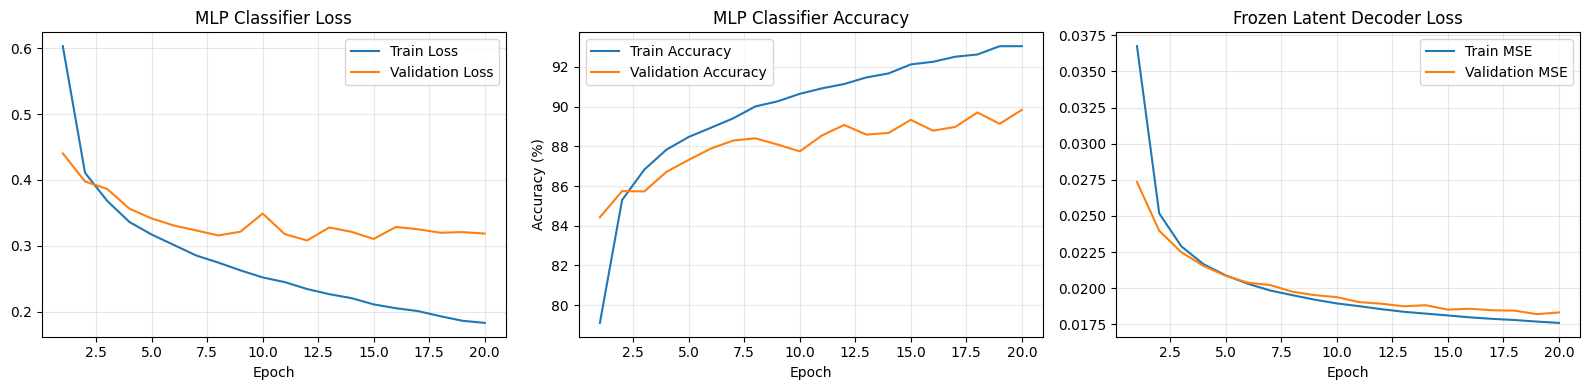

MLP Experiment Complete!
Classifier Accuracy: 89.33%
Frozen Decoder Test MSE: 0.018117
Saved outputs to: /content/drive/MyDrive/Model_Comparison/outputs/mlp_classifier


In [ ]:
# Loss

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

epochs = range(1, EPOCHS + 1)

axes[0].plot(
    epochs, mlp_train_losses,
    label="Train Loss"
)

axes[0].plot(
    epochs, mlp_val_losses,
    label="Validation Loss"
)

axes[0].set_title("MLP Classifier Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    np.array(mlp_train_accuracies) * 100,
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    np.array(mlp_val_accuracies) * 100,
    label="Validation Accuracy"
)

axes[1].set_title("MLP Classifier Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    epochs,
    decoder_train_losses,
    label="Train MSE"
)

axes[2].plot(
    epochs,
    decoder_val_losses,
    label="Validation MSE"
)

axes[2].set_title("Frozen Latent Decoder Loss")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("MLP Experiment Complete!")
print("Classifier Accuracy:", f"{mlp_test_accuracy * 100:.2f}%")
print("Frozen Decoder Test MSE:", f"{mlp_decoder_test_mse:.6f}")
print("Saved outputs to:", OUTPUT_DIR)
